# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. 

Adapted from your existing exercise. Previous local outputs were cleared so new Colab runs provide their own evidence. 

Source: Original local package: 01_google_mlcc/06_subject_independent_evaluation.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '01_google_mlcc', 'basic', '06_subject_independent_evaluation.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/01_google_mlcc
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/01_google_mlcc/results


# LO4 application: subject-independent evaluation
An original application of the Google MLCC lessons to the learning plan. All signals here are **synthetic teaching data**, not WESAD or Emognition results. Each example is an independent simulated trial, so overlapping windows cannot cross splits. Choose the split before fitting imputation or scaling.
Source concepts: https://developers.google.com/machine-learning/crash-course/overfitting/dividing-datasets


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut,GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from wearable_utils import make_wearable_windows,feature_matrix,classification_report_values
x,y,subjects=make_wearable_windows()
features=feature_matrix(x);all_predictions=np.full(y.shape,-1);rows=[];audit=[]
results=Path('results');results.mkdir(exist_ok=True)

## Leave-one-subject-out evaluation with an inner subject split


 subject  selected_C  macro_f1  balanced_accuracy
       0        10.0  0.694537           0.694444
       1        10.0  0.166667           0.333333
       2        10.0  0.166667           0.333333
       3         0.1  0.421801           0.444444
       4        10.0  0.173913           0.333333
       5         0.1  0.561905           0.583333
       6         0.1  0.166667           0.333333
       7         0.1  0.634986           0.638889
Mean per-subject metrics: {'macro_f1': 0.373392798169809, 'balanced_accuracy': 0.4618055555555556}
Pooled out-of-fold metrics: {'macro_f1': 0.4420531654899489, 'balanced_accuracy': 0.4618055555555555}


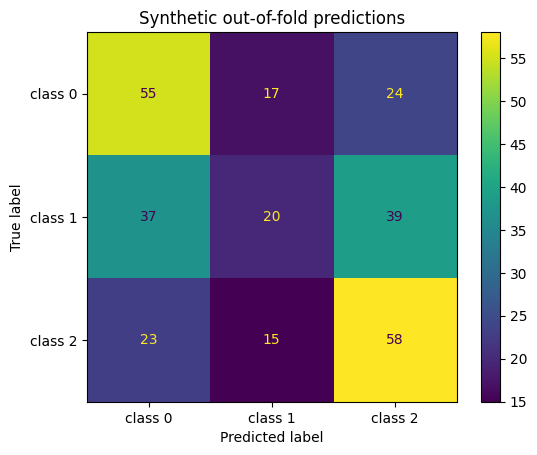

In [3]:
for fold,(train_val,test) in enumerate(LeaveOneGroupOut().split(features,y,subjects)):
    inner=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=42)
    tr_local,va_local=next(inner.split(features[train_val],y[train_val],subjects[train_val]))
    train,valid=train_val[tr_local],train_val[va_local]
    train_groups=set(subjects[train]);valid_groups=set(subjects[valid]);test_groups=set(subjects[test])
    assert train_groups.isdisjoint(valid_groups|test_groups) and valid_groups.isdisjoint(test_groups)
    candidates=[]
    for regularization in [.1,1.,10.]:
        model=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),
            LogisticRegression(C=regularization,class_weight='balanced',max_iter=500,random_state=42))
        model.fit(features[train],y[train]);pred=model.predict(features[valid])
        candidates.append((classification_report_values(y[valid],pred)['macro_f1'],regularization))
    _,best_C=max(candidates)
    final=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),
        LogisticRegression(C=best_C,class_weight='balanced',max_iter=500,random_state=42))
    final.fit(features[train_val],y[train_val])
    pred=final.predict(features[test]);all_predictions[test]=pred
    rows.append({'subject':int(subjects[test][0]),'selected_C':best_C,**classification_report_values(y[test],pred)})
    audit.append({'fold':fold,'inner_train_subjects':sorted(map(int,train_groups)),
        'inner_validation_subjects':sorted(map(int,valid_groups)),'test_subjects':sorted(map(int,test_groups))})
assert (all_predictions>=0).all()
table=pd.DataFrame(rows)
table.to_csv(results/'synthetic_loso_metrics.csv',index=False)
(results/'synthetic_loso_split_audit.json').write_text(json.dumps(audit,indent=2))
print(table.to_string(index=False))
print('Mean per-subject metrics:',table[['macro_f1','balanced_accuracy']].mean().to_dict())
print('Pooled out-of-fold metrics:',classification_report_values(y,all_predictions))
ConfusionMatrixDisplay(confusion_matrix(y,all_predictions,labels=[0,1,2]),display_labels=['class 0','class 1','class 2']).plot()
plt.title('Synthetic out-of-fold predictions');plt.show()

## Interpretation
The mean per-subject score weights participants equally. The pooled score weights examples equally; the two need not match. Hyperparameters are chosen inside each outer fold. A real dataset integration must also record participant IDs, session/trial IDs, label definitions, sensor rates, exclusion rules and data licences. Never tune on outer-test results. Do not describe this synthetic experiment as benchmark replication.


Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

In [4]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [5]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
}
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null}
